Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device : cuda
caractères dans le texte : 209131
10.812768 M paramètres
step 0: train loss 4.7457, val loss 4.7285
step 500: train loss 1.6435, val loss 1.9384
step 1000: train loss 1.1508, val loss 1.6226
step 1500: train loss 0.9004, val loss 1.6053
step 2000: train loss 0.6739, val loss 1.7277
step 2500: train loss 0.4603, val loss 1.9193
step 3000: train loss 0.2889, val loss 2.1605
step 3500: train loss 0.1739, val loss 2.3887
step 4000: train loss 0.1167, val loss 2.6332
step 4500: train loss 0.0907, val loss 2.8357
step 4999: train loss 0.0790, val loss 2.9720


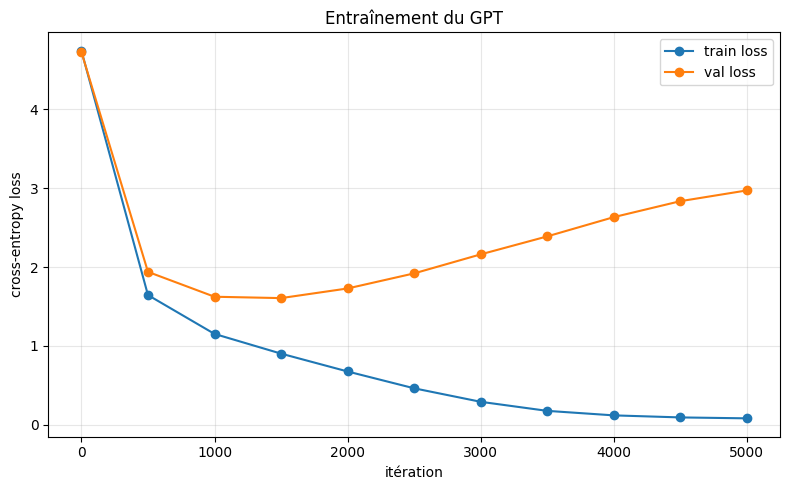


more flame burns to see brightly in the products, 
even the nature, and that the other part above the basin like 
iron filings with contains nothing but air as 
the look has for abseen of finger. We also observe disconsidered 
that the matterial conditions.

A discusse this lectures we can produce somethis in a candle, and 
you will see when we find there will shown it in a 
certain darkess, whether solid substance be into the uxten 
of the common kind the vapor. Obser when I tell 
had burns the cup which is, it over the place which is coursed 
formed if the put air is wonderful conditions 
respects that the condition of the same amount of a tipes to 
float. They are flowing by volume throught. In this water, 
one of the black smell, but the vaporized wax and see the tip 
with sides of the wick. The wax has the flame melts the wick 
with the flame and turns into the other eventually. It 
is a very pretty thing to see necess.
The shape is not soot as the smoke it imperfect combustion. 

In [4]:
import os
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

# dossier du projet dans le Drive : les données y sont lues, les résultats y sont enregistrés
PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/karpathy_tuto'

# ---------------- hyperparamètres ----------------
# Config "GPU" (comme Karpathy, ~10M paramètres, val loss ~1.48).
# Sur CPU, c'est TRES lent : utilise plutôt la config "CPU" ci-dessous.
batch_size = 64      # nombre de séquences traitées en parallèle (B)
block_size = 256     # longueur max du contexte (T)
max_iters = 5000
eval_interval = 500
learning_rate = 3e-4
eval_iters = 200
n_embd = 384         # taille du vecteur de chaque token (C)
n_head = 6           # nombre de têtes d'attention (384 / 6 = 64 par tête)
n_layer = 6          # nombre de blocs Transformer empilés
dropout = 0.2

# Config "CPU" (décommente pour tester vite sur un ordinateur portable) :
# batch_size, block_size, n_embd, n_head, n_layer, max_iters = 32, 64, 64, 4, 4, 3000

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():   # Mac Apple Silicon
    device = 'mps'
else:
    device = 'cpu'
print("device :", device)
# --------------------------------------------------

torch.manual_seed(1337)

# wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
!pip install -q pypdf
from pypdf import PdfReader

reader = PdfReader(os.path.join(PROJECT_DIR, 'input.pdf'))
text = "\n".join(page.extract_text() or "" for page in reader.pages)
print("caractères dans le texte :", len(text))

# tokenizer au niveau caractère
chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]            # str -> liste d'entiers
decode = lambda l: ''.join([itos[i] for i in l])   # liste d'entiers -> str

# split train / val
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]


def get_batch(split):
    """Tire batch_size morceaux aléatoires de longueur block_size."""
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)


@torch.no_grad()
def estimate_loss():
    """Loss moyenne sur plusieurs batches, pour train et val."""
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out


class Head(nn.Module):
    """Une tête de self-attention (masquée)."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)     # (B, T, head_size)
        q = self.query(x)   # (B, T, head_size)
        # scores d'affinité, mis à l'échelle par 1/sqrt(head_size)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5   # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)   # (B, T, head_size)
        return wei @ v      # (B, T, head_size)


class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, puis projection."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)   # (B, T, n_embd)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    """Petit MLP appliqué à chaque token séparément."""

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Bloc Transformer : communication (attention) puis calcul (feed-forward)."""

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # connexion résiduelle + pre-norm
        x = x + self.ffwd(self.ln2(x))
        return x


class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)          # layer norm finale
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                                # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device))  # (T, C)
        x = tok_emb + pos_emb        # (B, T, C)
        x = self.blocks(x)           # (B, T, C)
        x = self.ln_f(x)             # (B, T, C)
        logits = self.lm_head(x)     # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]          # on garde au plus block_size tokens
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]                # dernier pas de temps -> (B, C)
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)   # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1)              # (B, T+1)
        return idx


model = GPTLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M paramètres")

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

# historique des losses, pour tracer la courbe à la fin
steps, train_losses, val_losses = [], [], []

for iter in range(max_iters):
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        steps.append(iter)
        train_losses.append(losses['train'].item())
        val_losses.append(losses['val'].item())

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# ---------------- courbe train / val ----------------
plt.figure(figsize=(8, 5))
plt.plot(steps, train_losses, marker='o', label='train loss')
plt.plot(steps, val_losses, marker='o', label='val loss')
plt.xlabel('itération')
plt.ylabel('cross-entropy loss')
plt.title('Entraînement du GPT')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'loss_curve.png'), dpi=150)   # image pour le README
plt.show()

# ---------------- sauvegarde des poids ----------------
torch.save(model.state_dict(), os.path.join(PROJECT_DIR, 'gpt_model.pt'))

# ---------------- génération ----------------
context = torch.zeros((1, 1), dtype=torch.long, device=device)
sample = decode(model.generate(context, max_new_tokens=1000)[0].tolist())
print(sample)
with open(os.path.join(PROJECT_DIR, 'sample_output.txt'), 'w', encoding='utf-8') as f:
    f.write(sample)

print("Fichiers enregistrés dans :", PROJECT_DIR)


In [5]:
!ls /content/drive/MyDrive

 014538e0-89d9-495a-a245-6e2a0b90b281.jpg
'2023 (1).docx'
 2023.docx
'7C-80-RH-EQS-015-Evaluation Compétences QHSE_V3.0.gdoc'
 abalone_test.gsheet
'Attestation CVEC 2026-2027 (1).pdf'
'Attestation CVEC 2026-2027.pdf'
 Attestation_decision_favorable_08-07-2025.pdf
 attestation-honneur-non-ressources.docx
'Attestation sur l’honneur de non détention d’ASSR.gdoc'
'Automatic packaging powder machine.gdoc'
 Blabla.gdoc
'Budget activité Yougive tshirts custom.gsheet'
"BUDGET GIV'WORKSHOP.gsheet"
"BUDGET GIV'WORKSHOP.xlsx"
'Cahier des charges pour l.pdf'
 CAP2024.docx
'Charte de vie signée.gdoc'
'ChatGPT Image 7 mai 2025, 00_05_07.gdoc'
'Clean wave strat.gdoc'
'Colab Notebooks'
'Commande elec LeroyMerlin.gsheet'
 Commandes.gdoc
'Commandes IOT.gsheet'
'Compte rendue Reunion 25 03 2025 à 21h.gdoc'
'Copie de Décodage entreprise.pptx - Graphique à secteurs 1.gsheet'
'Copie de Microgrid_Analysis_Report.docx.gdoc'
'Copy of EEE LAB Skills.gdoc'
'Copy of Rapport 25 01 2023.gdoc'
'Copy of You-Gi